In [17]:
from itertools import islice
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, median_filter

ROOT = Path("../../../data/raw/floor_posture_dataset").resolve()
if not (ROOT / "data").is_dir():
    raise FileNotFoundError(f"Dataset not found: {ROOT}")
if str(ROOT / "recorder") not in sys.path:
    sys.path.insert(0, str(ROOT / "recorder"))
from loguru import logger
from vt_radar.data.dataset import TLVDataset

logger.disable("vt_radar")

In [18]:
def load_heatmap_stack(frames):
    '''(n_frames, range_bins, doppler_bins) array of raw heatmaps.'''
    return np.stack([np.asarray(f.output.range_doppler_heatmap, dtype=float) for f in frames])


def load_camera_stack(frames):
    '''(n_frames, H, W, 3) array of camera images, frame-aligned with load_heatmap_stack
    when given the SAME `frames` list.'''
    return np.stack([np.asarray(f.image) for f in frames])


class Filter:
    '''One preprocessing step over a (frames, range, doppler) heatmap stack.
    Subclasses implement `apply`; parameters live as plain attributes set in
    `__init__`, so change them freely per instance (e.g. `Gaussian(sigma=2)`).
    Stack several with `Pipeline([...])`.'''
    needs_bg = False

    def apply(self, heats, bg=None):
        raise NotImplementedError

    def __call__(self, heats, bg=None):
        return self.apply(heats, bg=bg)

    @property
    def label(self):
        return type(self).__name__.lower()

    def __repr__(self):
        return self.label


class NoneFilter(Filter):
    '''Baseline: pass heatmaps through unchanged.'''
    label = "none"

    def apply(self, heats, bg=None):
        return heats


class BgSubtract(Filter):
    '''Subtract the frame-averaged background of a matching empty-room recording.'''
    needs_bg = True
    label = "bg_subtract"

    def apply(self, heats, bg=None):
        if bg is None:
            raise ValueError("BgSubtract requires bg=<empty-room heatmap stack>")
        bg_mean = bg.mean(axis=0)
        return np.clip(heats - bg_mean, 0, None)


class Gaussian(Filter):
    '''Spatial: blur within each frame.'''

    def __init__(self, sigma=1):
        self.sigma = sigma

    @property
    def label(self):
        return f"gaussian(sigma={self.sigma})"

    def apply(self, heats, bg=None):
        return np.stack([gaussian_filter(h, sigma=self.sigma) for h in heats])


class Median(Filter):
    '''Spatial: kill speckle within each frame.'''

    def __init__(self, size=3):
        self.size = size

    @property
    def label(self):
        return f"median(size={self.size})"

    def apply(self, heats, bg=None):
        return np.stack([median_filter(h, size=self.size) for h in heats])


class MovingAvg(Filter):
    '''Temporal: rolling mean over time, per bin.'''

    def __init__(self, window=5):
        self.window = window

    @property
    def label(self):
        return f"moving_avg(window={self.window})"

    def apply(self, heats, bg=None):
        pad = self.window // 2
        padded = np.pad(heats, ((pad, pad), (0, 0), (0, 0)), mode="edge")
        kernel = np.ones(self.window) / self.window
        return np.apply_along_axis(lambda x: np.convolve(x, kernel, mode="valid"), axis=0, arr=padded)


class Ema(Filter):
    '''Temporal: exponential moving average over time.'''

    def __init__(self, alpha=0.3):
        self.alpha = alpha

    @property
    def label(self):
        return f"ema(alpha={self.alpha})"

    def apply(self, heats, bg=None):
        out = np.empty_like(heats)
        out[0] = heats[0]
        for i in range(1, len(heats)):
            out[i] = self.alpha * heats[i] + (1 - self.alpha) * out[i - 1]
        return out


class Pipeline(Filter):
    '''Chain several filters, applied in order, e.g. Pipeline([BgSubtract(), Ema()]).'''

    def __init__(self, steps):
        self.steps = list(steps)

    @property
    def needs_bg(self):
        return any(step.needs_bg for step in self.steps)

    @property
    def label(self):
        return "+".join(step.label for step in self.steps)

    def apply(self, heats, bg=None):
        for step in self.steps:
            heats = step.apply(heats, bg=bg)
        return heats

In [19]:
REC_TO_PLAY = "Config_2__Exp_1__11_02_2023__reduceClutter_Artem"
MAX_FRAMES = 100

def rec_dir(name):
    matches = sorted((ROOT / "data").glob(f"*/{name}"))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one recording named {name!r}.")
    return matches[0]

def load_bg_stack(rec, max_frames):
    # Match config and room; ignore metadata rows whose recordings are absent.
    shapes = pd.read_csv(ROOT / "HEATMAP_SHAPES.csv")
    foreground = shapes.loc[shapes["rec"] == rec].iloc[0]
    candidates = shapes.loc[
        (shapes["cfg"] == foreground["cfg"])
        & (shapes["room"] == foreground["room"])
        & shapes["rec"].str.endswith("_environment")
    ]
    for name in candidates["rec"]:
        if list((ROOT / "data").glob(f"*/{name}")):
            bg_frames = list(islice(iter(TLVDataset(str(rec_dir(name)))), max_frames))
            return load_heatmap_stack(bg_frames)
    raise ValueError(f"No matching empty-room recording for {rec!r}.")

play_ds = TLVDataset(str(rec_dir(REC_TO_PLAY)))
sensor = play_ds.config.sensor() if play_ds.config else None
frames = list(islice(iter(play_ds), MAX_FRAMES))
raw = load_heatmap_stack(frames)
camera = load_camera_stack(frames)

REPORT_FRAME = 21  # change to any loaded frame index

METHODS = [
    NoneFilter(),
    BgSubtract(),
    Pipeline([BgSubtract(), Ema()]),
    Pipeline([BgSubtract(), Gaussian(sigma=1)]),
    Pipeline([Ema(alpha=0.8), Gaussian(sigma=1)]),
    Median(),
    MovingAvg(),
]

methods = list(METHODS)
try:
    bg = load_bg_stack(REC_TO_PLAY, MAX_FRAMES)
except ValueError as exc:
    print(f"Skipping background-subtraction methods: {exc}")
    bg = None
    methods = [method for method in methods if not method.needs_bg]
stacks = {method.label: method.apply(raw, bg=bg) for method in methods}

In [20]:
import matplotlib.animation as animation
from IPython.display import HTML

def animate_doppler_grid(named_stacks, camera=None, interval=200, sensor=None):
    '''Play several (frames, range, doppler) stacks side by side, frame-synced.
    Pass `camera` (frames x H x W x 3) to show the camera feed as the first panel,
    so you can see what actually happened next to each smoothing method.

    Each stack is oriented the same way as RangeDoppler._plot_heatmap: doppler
    centred on 0 m/s (fftshift) and range increasing away from the sensor
    (flipud). Pass `sensor` to also label the axes in physical units.'''
    names = list(named_stacks)
    logged = {
        name: np.flip(np.fft.fftshift(np.log1p(named_stacks[name]), axes=2), axis=1)
        for name in names
    }
    n_frames = min(h.shape[0] for h in logged.values())
    if camera is not None:
        n_frames = min(n_frames, len(camera))

    extent = None
    if sensor is not None:
        extent = (min(sensor.doppler_bins), max(sensor.doppler_bins), 0, max(sensor.range_bins))

    n_panels = len(names) + (1 if camera is not None else 0)
    fig, axes = plt.subplots(1, n_panels, figsize=(3.4 * n_panels, 4.2))
    axes = np.atleast_1d(axes)

    ims = []
    ax_i = 0
    if camera is not None:
        cam_im = axes[ax_i].imshow(camera[0])
        axes[ax_i].set_title("camera")
        axes[ax_i].set_xticks([]); axes[ax_i].set_yticks([])
        ims.append(("camera", cam_im))
        ax_i += 1
    for name in names:
        h = logged[name]
        im = axes[ax_i].imshow(h[0], aspect="auto", cmap="magma", vmin=h.min(), vmax=h.max(), extent=extent)
        axes[ax_i].set_title(name)
        axes[ax_i].set_xlabel("Doppler (m/s)" if extent is not None else "doppler bin")
        ims.append((name, im))
        ax_i += 1
    axes[1 if camera is not None else 0].set_ylabel("Range (m)" if extent is not None else "range bin")
    suptitle = fig.suptitle("frame 0")
    plt.tight_layout()

    def update(i):
        for name, im in ims:
            im.set_data(camera[i] if name == "camera" else logged[name][i])
        suptitle.set_text(f"frame {i} / {n_frames}")
        return [im for _, im in ims] + [suptitle]

    anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=interval, blit=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())

animate_doppler_grid(stacks, camera=camera, interval=MAX_FRAMES, sensor=sensor)

Animation size has reached 20973871 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


Saved: /home/efeoz/ai-engineering/notebook-figures/results/figures/doppler_filtering_Config_2__Exp_1__11_02_2023__reduceClutter_Artem_frame_0021.png


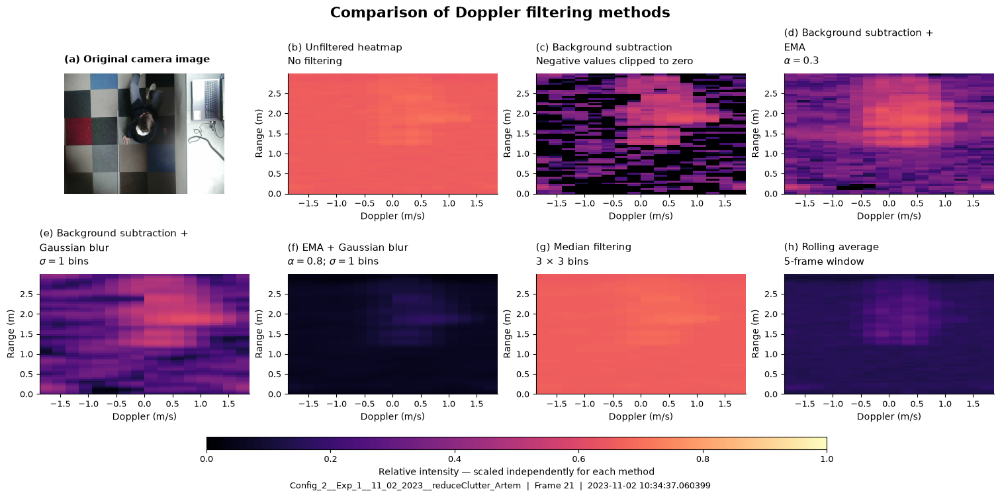

In [21]:
# Filtering comparison: display and save a 300 dpi PNG.
from pathlib import Path
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import math
import textwrap

REPORT_DIR = Path(ROOT).resolve().parents[2] / "results" / "figures"

if not 0 <= REPORT_FRAME < len(camera):
    raise IndexError(f"Choose REPORT_FRAME between 0 and {len(camera) - 1}.")

# Match the animation: each method uses its log-value min/max over all loaded frames.
report_methods = [method for method in methods if method.label in stacks]
report_maps = {
    method.label: np.flipud(np.fft.fftshift(
        np.log1p(stacks[method.label][REPORT_FRAME]), axes=1))
    for method in report_methods
}
report_norms = {}
for method in report_methods:
    logged_stack = np.log1p(stacks[method.label])
    report_norms[method.label] = Normalize(
        vmin=float(logged_stack.min()), vmax=float(logged_stack.max()),
    )

def report_method_title(method):
    if isinstance(method, NoneFilter):
        return "Unfiltered heatmap", "No filtering"
    if isinstance(method, BgSubtract):
        return "Background subtraction", "Negative values clipped to zero"
    if isinstance(method, Gaussian):
        return "Gaussian blur", rf"$\sigma = {method.sigma}$ bins"
    if isinstance(method, Median):
        return "Median filtering", f"{method.size} × {method.size} bins"
    if isinstance(method, MovingAvg):
        return "Rolling average", f"{method.window}-frame window"
    if isinstance(method, Ema):
        return "EMA", rf"$\alpha = {method.alpha}$"
    if isinstance(method, Pipeline):
        parts = [report_method_title(step) for step in method.steps]
        return " + ".join(p[0] for p in parts), "; ".join(
            p[1] for step, p in zip(method.steps, parts) if not isinstance(step, BgSubtract)
        )
    return method.label, ""

report_extent = None
if sensor is not None:
    report_extent = (min(sensor.doppler_bins), max(sensor.doppler_bins),
                     0, max(sensor.range_bins))

report_count = len(report_methods) + 1
report_columns = min(4, report_count)
report_rows = math.ceil(report_count / report_columns)
with plt.rc_context({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
                     "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "savefig.facecolor": "white"}):
    report_fig, report_axes = plt.subplots(
        report_rows, report_columns, figsize=(15, 3.7 * report_rows),
        squeeze=False, layout="constrained", facecolor="white",
    )
    report_axes = report_axes.ravel()
    image = np.asarray(camera[REPORT_FRAME])
    if image.size and image.ndim in (2, 3):
        report_axes[0].imshow(image)
    else:
        report_axes[0].text(0.5, 0.5, "No camera image", ha="center", va="center")
    report_axes[0].set_title("(a) Original camera image", loc="left", fontweight="bold", pad=12)
    report_axes[0].set_axis_off()

    heat_axes = []
    for panel, method in enumerate(report_methods, start=1):
        ax = report_axes[panel]
        heat_image = ax.imshow(
            report_maps[method.label], cmap="magma", norm=report_norms[method.label],
            extent=report_extent, origin="upper", aspect="auto", interpolation="nearest",
        )
        title, parameters = report_method_title(method)
        title = textwrap.fill(f"({chr(97 + panel)}) {title}", width=31)
        ax.set_title(title + "\n" + parameters, loc="left", pad=10, linespacing=1.35)
        ax.set_xlabel("Doppler (m/s)" if sensor is not None else "Centered Doppler bin")
        ax.set_ylabel("Range (m)" if sensor is not None else "Range bin")
        ax.spines[["top", "right"]].set_visible(False)
        heat_axes.append(ax)

    for ax in report_axes[report_count:]:
        ax.set_visible(False)

    report_fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap="magma"), ax=heat_axes, orientation="horizontal", shrink=0.65, pad=0.04, aspect=50,
                        label="Relative intensity — scaled independently for each method")
    report_fig.suptitle("Comparison of Doppler filtering methods", fontsize=16, fontweight="bold")
    report_fig.supxlabel(
        f"{REC_TO_PLAY}  |  Frame {REPORT_FRAME}  |  {frames[REPORT_FRAME].timestamp}", fontsize=9,
    )

    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    report_stem = REPORT_DIR / f"doppler_filtering_{REC_TO_PLAY}_frame_{REPORT_FRAME:04d}"
    output = report_stem.with_suffix(".png")
    report_fig.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved: {output}")
    plt.show()

Saved: /home/efeoz/ai-engineering/notebook-figures/results/figures/encoder_layers_Config_2__Exp_1__11_02_2023__reduceClutter_Artem_frame_0021.png


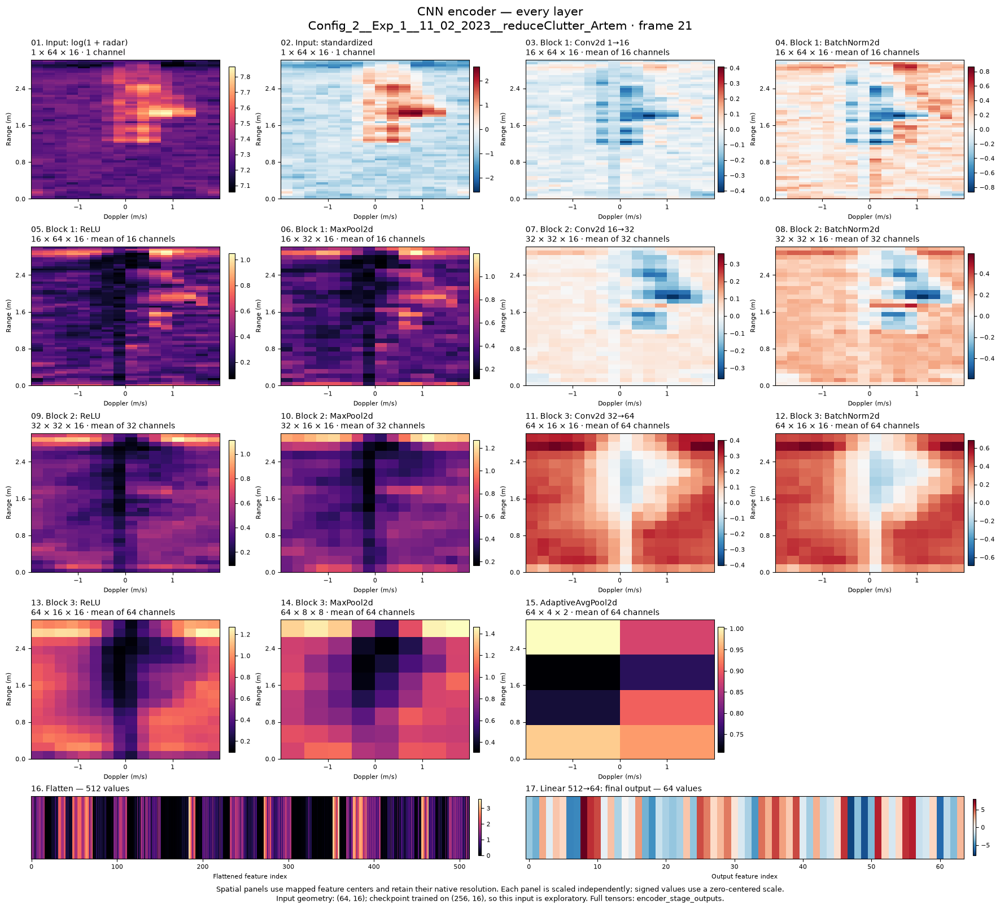

In [22]:
# Every encoder layer for the SAME recording/frame as the main filtering figure.
import math
from collections import OrderedDict
import torch
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator

ENCODER_REPO = Path(ROOT).resolve().parents[2]
if str(ENCODER_REPO / "src") not in sys.path:
    sys.path.insert(0, str(ENCODER_REPO / "src"))
from models.rnn import RNN

ENCODER_CHECKPOINT = ENCODER_REPO.parent / "ai-engineering/results/training/20261014-232714-503293/rnn.pt"
ENCODER_CHANNEL = None  # None = channel mean; 0--15 selects a common learned channel
ENCODER_COLUMNS = 4
ENCODER_SAVE = True     # save a 300 dpi PNG alongside the main filtering figure

if not 0 <= REPORT_FRAME < len(raw):
    raise IndexError(f"REPORT_FRAME must be between 0 and {len(raw) - 1}.")
encoder_model, _ = RNN.load(ENCODER_CHECKPOINT)
encoder_model.net.eval()
encoder = encoder_model.net.encoder
encoder_input = torch.as_tensor(np.log1p(raw[REPORT_FRAME]).astype(np.float32),
                                 device=encoder_model.device)[None, None, None, :, :]

# Native input-bin centers are propagated through the actual layer geometry.
def encoder_advance_centers(layer, centers):
    def dim(value, axis):
        return value[axis] if isinstance(value, tuple) else value
    result = [axis.copy() for axis in centers]
    if isinstance(layer, (torch.nn.Conv2d, torch.nn.MaxPool2d)):
        for axis in range(2):
            previous = centers[axis]
            kernel, padding, dilation = (dim(getattr(layer, name), axis)
                                         for name in ("kernel_size", "padding", "dilation"))
            stride = dim(layer.stride if layer.stride is not None else layer.kernel_size, axis)
            count = (len(previous) + 2 * padding - dilation * (kernel - 1) - 1) // stride + 1
            positions = np.arange(count) * stride - padding + (kernel - 1) * dilation / 2
            result[axis] = previous[0] + positions * (previous[1] - previous[0])
    elif isinstance(layer, torch.nn.AdaptiveAvgPool2d):
        for axis in range(2):
            previous = centers[axis]
            count = dim(layer.output_size, axis) or len(previous)
            starts = np.floor(np.arange(count) * len(previous) / count).astype(int)
            stops = np.ceil((np.arange(count) + 1) * len(previous) / count).astype(int)
            result[axis] = np.array([previous[a:b].mean() for a, b in zip(starts, stops)])
    elif isinstance(layer, torch.nn.Flatten):
        return None
    elif not isinstance(layer, (torch.nn.BatchNorm2d, torch.nn.ReLU)):
        raise ValueError(f"Spatial mapping is not defined for {type(layer).__name__}.")
    return result

def encoder_axis_edges(centers):
    centers = np.asarray(centers, dtype=float)
    return np.concatenate((
        [centers[0] - (centers[1] - centers[0]) / 2],
        (centers[:-1] + centers[1:]) / 2,
        [centers[-1] + (centers[-1] - centers[-2]) / 2],
    ))

# Full, unaveraged tensors are retained here; only spatial plotting averages channels.
encoder_stage_outputs = OrderedDict()
encoder_stage_coordinates = {}
encoder_input_centers = [np.arange(size, dtype=float) for size in raw.shape[1:]]
encoder_stage_outputs["Input: log(1 + radar)"] = encoder_input[0, 0].cpu().numpy().copy()
encoder_stage_coordinates["Input: log(1 + radar)"] = encoder_input_centers
encoder_stage_coordinates["Input: standardized"] = encoder_input_centers

def encoder_capture(name):
    def hook(module, inputs, output):
        encoder_stage_outputs[name] = output.detach().cpu().clone()[0].numpy()
    return hook

def encoder_capture_standardized(module, inputs):
    encoder_stage_outputs["Input: standardized"] = inputs[0].detach().cpu().clone()[0].numpy()

encoder_handles = []
encoder_centers = encoder_input_centers
encoder_block = 0
try:
    encoder_handles.append(encoder.conv[0].register_forward_pre_hook(encoder_capture_standardized))
    for layer in encoder.conv:
        if isinstance(layer, torch.nn.Conv2d):
            encoder_block += 1
            name = f"Block {encoder_block}: Conv2d {layer.in_channels}→{layer.out_channels}"
        elif isinstance(layer, (torch.nn.BatchNorm2d, torch.nn.ReLU, torch.nn.MaxPool2d)):
            name = f"Block {encoder_block}: {type(layer).__name__}"
        else:
            name = type(layer).__name__
        encoder_centers = encoder_advance_centers(layer, encoder_centers)
        encoder_stage_coordinates[name] = encoder_centers
        encoder_handles.append(layer.register_forward_hook(encoder_capture(name)))
    encoder_final_name = f"Linear {encoder.fc.in_features}→{encoder.fc.out_features}: final output"
    encoder_stage_coordinates[encoder_final_name] = None
    encoder_handles.append(encoder.fc.register_forward_hook(encoder_capture(encoder_final_name)))
    with torch.inference_mode():
        encoder_final_output = encoder(encoder_input).detach().cpu()
finally:
    for handle in encoder_handles:
        handle.remove()

# Use the recording's calibration; fall back to bin coordinates if unavailable.
if sensor is not None:
    encoder_range_bins = np.asarray(sensor.range_bins, dtype=float)
    encoder_velocity_bins = np.asarray(sensor.doppler_bins, dtype=float)
    encoder_x_label, encoder_y_label = "Doppler (m/s)", "Range (m)"
else:
    encoder_range_bins = np.arange(raw.shape[1], dtype=float)
    encoder_velocity_bins = np.fft.fftshift(np.fft.fftfreq(raw.shape[2]) * raw.shape[2])
    encoder_x_label, encoder_y_label = "Centered Doppler bin", "Range bin"
if raw.shape[1:] != (len(encoder_range_bins), len(encoder_velocity_bins)):
    raise ValueError("Radar coordinates do not match the input heatmap.")
encoder_dr = float(np.diff(encoder_range_bins).mean())
encoder_dv = float(np.diff(encoder_velocity_bins).mean())
if not (np.allclose(np.diff(encoder_range_bins), encoder_dr)
        and np.allclose(np.diff(encoder_velocity_bins), encoder_dv)):
    raise ValueError("This layer-to-radar mapping requires uniformly spaced sensor bins.")
encoder_velocity_edges = encoder_axis_edges(encoder_velocity_bins)
encoder_range_edges = encoder_axis_edges(encoder_range_bins)
encoder_velocity_origin = encoder_velocity_edges[0]
encoder_velocity_zero = np.fft.ifftshift(encoder_velocity_bins)[0]
encoder_velocity_period = len(encoder_velocity_bins) * encoder_dv

def encoder_plot_style(values):
    low, high = float(values.min()), float(values.max())
    if low < 0:
        limit = max(abs(low), abs(high)) or 1
        return "RdBu_r", Normalize(-limit, limit)
    return "magma", Normalize(low, high if high > low else low + 1)

encoder_spatial_stages = [(name, values) for name, values in encoder_stage_outputs.items() if values.ndim == 3]
encoder_vector_stages = [(name, values) for name, values in encoder_stage_outputs.items() if values.ndim == 1]
encoder_spatial_rows = math.ceil(len(encoder_spatial_stages) / ENCODER_COLUMNS)
with plt.rc_context({"font.size": 8, "axes.titlesize": 10, "axes.labelsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8}):
    encoder_fig = plt.figure(figsize=(4.4 * ENCODER_COLUMNS, 3.5 * encoder_spatial_rows + 2),
                             layout="constrained", facecolor="white")
    encoder_grid = encoder_fig.add_gridspec(encoder_spatial_rows + 1, ENCODER_COLUMNS,
                                           height_ratios=[1] * encoder_spatial_rows + [0.45])
    encoder_plot_axes = []
    for index, (name, values) in enumerate(encoder_spatial_stages):
        ax = encoder_fig.add_subplot(encoder_grid[index // ENCODER_COLUMNS, index % ENCODER_COLUMNS])
        encoder_plot_axes.append(ax)
        channels = values.shape[0]
        if channels == 1:
            display = values[0]
            channel_label = "1 channel"
        elif ENCODER_CHANNEL is None:
            display = values.mean(axis=0)
            channel_label = f"mean of {channels} channels"
        else:
            if not isinstance(ENCODER_CHANNEL, int) or not 0 <= ENCODER_CHANNEL < channels:
                raise ValueError(f"Choose a channel from 0 to {channels - 1} for {name}.")
            display = values[ENCODER_CHANNEL]
            channel_label = f"channel {ENCODER_CHANNEL} of {channels}"
        native_range, native_velocity = encoder_stage_coordinates[name]
        range_centers = encoder_range_bins[0] + native_range * encoder_dr
        velocity_centers = ((encoder_velocity_zero + native_velocity * encoder_dv - encoder_velocity_origin)
                            % encoder_velocity_period) + encoder_velocity_origin
        order = np.argsort(velocity_centers)
        display = display[:, order]
        cmap, norm = encoder_plot_style(display)
        image = ax.pcolormesh(encoder_axis_edges(velocity_centers[order]), encoder_axis_edges(range_centers),
                              display, shading="flat", cmap=cmap, norm=norm, rasterized=True)
        ax.set_xlim(encoder_velocity_edges[0], encoder_velocity_edges[-1])
        ax.set_ylim(0 if sensor is not None else encoder_range_edges[0], encoder_range_edges[-1])
        ax.set_xlabel(encoder_x_label)
        ax.set_ylabel(encoder_y_label)
        ax.set_title(f"{index + 1:02d}. {name}\n{' × '.join(map(str, values.shape))} · {channel_label}", loc="left")
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        encoder_fig.colorbar(image, ax=ax, shrink=0.9, pad=0.02)

    # Flatten and Linear have no range/Doppler axis. Show ALL values as 1-D strips.
    for index, (name, values) in enumerate(encoder_vector_stages):
        left = index * ENCODER_COLUMNS // len(encoder_vector_stages)
        right = (index + 1) * ENCODER_COLUMNS // len(encoder_vector_stages)
        ax = encoder_fig.add_subplot(encoder_grid[-1, left:right])
        encoder_plot_axes.append(ax)
        cmap, norm = encoder_plot_style(values)
        image = ax.imshow(values[None, :], aspect="auto", interpolation="nearest", cmap=cmap, norm=norm)
        ax.set_yticks([])
        ax.set_xlabel("Flattened feature index" if name == "Flatten" else "Output feature index")
        ax.set_title(f"{len(encoder_spatial_stages) + index + 1:02d}. {name} — {values.size} values", loc="left")
        encoder_fig.colorbar(image, ax=ax, shrink=0.9, pad=0.02)

    encoder_fig.suptitle(f"CNN encoder — every layer\n{REC_TO_PLAY} · frame {REPORT_FRAME}", fontsize=15)
    encoder_fig.supxlabel(
        "Spatial panels use mapped feature centers and retain their native resolution. "
        "Each panel is scaled independently; signed values use a zero-centered scale.\n"
        f"Input geometry: {tuple(raw.shape[1:])}; checkpoint trained on (256, 16), so this input is exploratory. "
        "Full tensors: encoder_stage_outputs.", fontsize=9,
    )
    if ENCODER_SAVE:
        encoder_output_dir = ENCODER_REPO / "results" / "figures"
        encoder_output_dir.mkdir(parents=True, exist_ok=True)
        encoder_png_path = encoder_output_dir / f"encoder_layers_{REC_TO_PLAY}_frame_{REPORT_FRAME:04d}.png"
        encoder_fig.savefig(encoder_png_path, dpi=300, bbox_inches="tight", facecolor="white")
        print(f"Saved: {encoder_png_path}")
    plt.show()